# Exercise 6.2 · Introduction to Keras

## Model and objective
The goal is to approximate a complicated single variable function from 10,000 noisy training examples. Inputs are sampled uniformly over [−10, 10]. The targets add independent Gaussian noise with standard deviation 1. The test targets are exact function values at 10,000 evenly spaced inputs. The model has eight hidden layers with 100 ReLU units each and a linear output for regression. Adam uses a learning rate of 0.001 and minimizes mean squared error, which penalizes large errors quadratically.

## Recorded results
The supplied run trained for 200 epochs with batches of 64. The learning curve drops rapidly at the start and then flattens near an MSE of 1. The recorded final training loss is 1.0395. This is close to the variance of the noise added to the targets. In the prediction panel, the network captures the broad shape, while the sharp peaks are harder to reproduce. The saved run did not print a separate noiseless test MSE.


| Epoch | Recorded training MSE |
| --- | --- |
| 1 | 1.1512 |
| 20 | 1.0934 |
| 40 | 1.0933 |
| 60 | 1.0696 |
| 80 | 1.0669 |
| 100 | 1.0518 |
| 120 | 1.0535 |
| 140 | 1.0486 |
| 160 | 1.0640 |
| 180 | 1.0371 |
| 200 | 1.0395 |

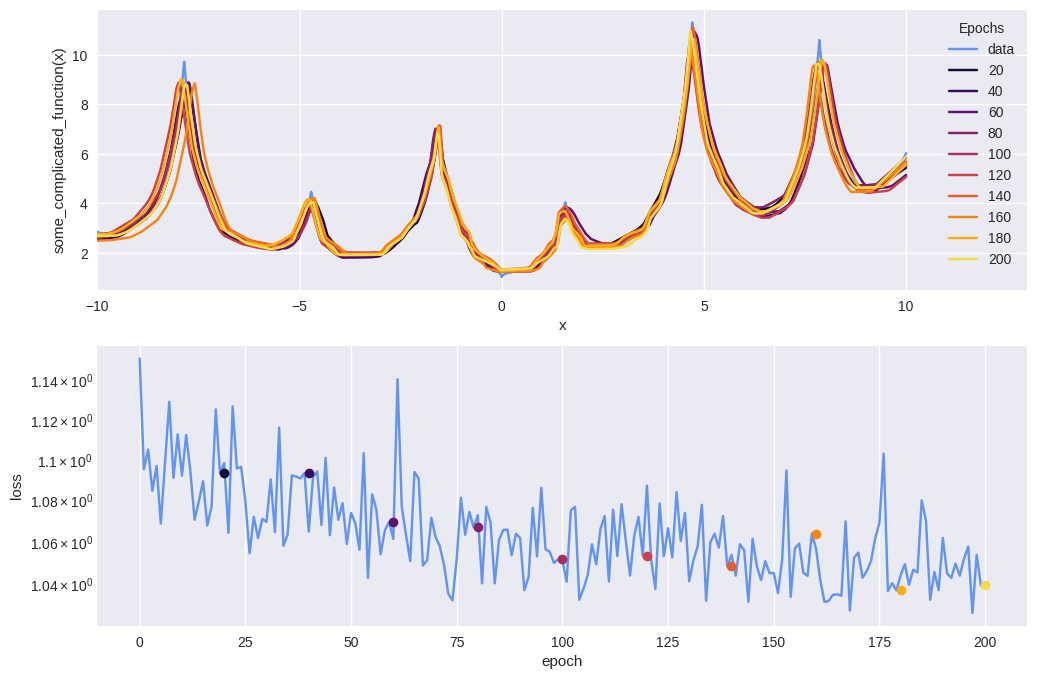

Figure 1. Saved prediction and training loss plots. Treat the epoch labels on the prediction curves as labels from the original export. The original callback stored every 20 batches and could overwrite files within each epoch. The corrected code below stores predictions at the end of every twentieth epoch.

## Reproducible code
This version fixes checkpoint timing, seeds the sampling and model initialization, and prints mean squared error on the noiseless test grid. A fresh run can produce different values from the recorded experiment above.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras


In [ ]:
# Prepare the training and test examples.
seed = 620
keras.utils.set_random_seed(seed)
rng = np.random.default_rng(seed)

def target(x):
    return (np.sqrt(np.abs(x)) + 0.1*x + 0.01*x**2 + 1
            - np.sin(x) + 0.5*np.exp(x/10)) / (0.5 + np.abs(np.cos(x)))

x_train = rng.uniform(-10, 10, (10_000, 1)).astype('float32')
y_train = (target(x_train) + rng.normal(size=x_train.shape)).astype('float32')
x_test = np.linspace(-10, 10, 10_000, dtype='float32').reshape(-1, 1)
y_test = target(x_test)


In [ ]:
# Define and compile the network.
model = keras.Sequential(
    [keras.Input(shape=(1,))]
    + [keras.layers.Dense(100, activation='relu') for _ in range(8)]
    + [keras.layers.Dense(1)]
)
model.compile(optimizer=keras.optimizers.Adam(0.001), loss='mse', steps_per_execution=32)
model.summary(line_length=75)

class RecordPredictions(keras.callbacks.Callback):
    def __init__(self, inputs):
        super().__init__()
        self.inputs = inputs
        self.predictions = {}

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % 20 == 0:
            self.predictions[epoch + 1] = self.model.predict(
                self.inputs, verbose=0
            ).ravel()


In [ ]:
# Train the network and save predictions.
snapshots = RecordPredictions(x_test)
history = model.fit(
    x_train, y_train, epochs=200, batch_size=64, callbacks=[snapshots], verbose=0
)
final_prediction = snapshots.predictions[200]
test_mse = np.mean((final_prediction - y_test.ravel())**2)
print(f"Final training MSE: {history.history['loss'][-1]:.4f}")
print(f"Noiseless test MSE: {test_mse:.4f}")


In [ ]:
# Plot the predictions and training loss.
fig, (prediction_ax, loss_ax) = plt.subplots(2, 1, figsize=(10, 8))
prediction_ax.plot(x_test.ravel(), y_test.ravel(), 'k', label='Exact target')
for epoch, predictions in snapshots.predictions.items():
    prediction_ax.plot(x_test.ravel(), predictions, label=str(epoch), alpha=0.8)
prediction_ax.set(xlabel='x', ylabel='Function value')
prediction_ax.legend(title='Epoch', ncol=3)
loss_ax.semilogy(np.arange(1, 201), history.history['loss'])
loss_ax.set(xlabel='Epoch', ylabel='Training MSE')
fig.tight_layout()
plt.show()


## Code that generated the saved figures
The following archived cells document how the original output was produced. They are included as a record. Run the corrected cells above to repeat the experiment.